# 🌳 Notebook 06.4: Hierarchical Clustering (Final Tiers)
## Objective
Because K-Means struggled with outliers, we used DBSCAN to natively detect and remove them. Now, we feed that perfectly clean dataset into **Agglomerative Hierarchical Clustering**.

By building a Dendrogram, we can visually prove exactly how the Ames market segments itself into standard suburban tiers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
import joblib
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# LOAD THE DBSCAN-CLEANED DATA
X_scaled = pd.read_csv('../../data/processed/X_cluster_clean_scaled.csv')
X_raw = pd.read_csv('../../data/processed/X_cluster_clean_raw.csv')

### 1. Generating the Dendrogram
Because DBSCAN already removed the noise, the Dendrogram should naturally and cleanly split the remaining normal houses into our distinct business tiers.

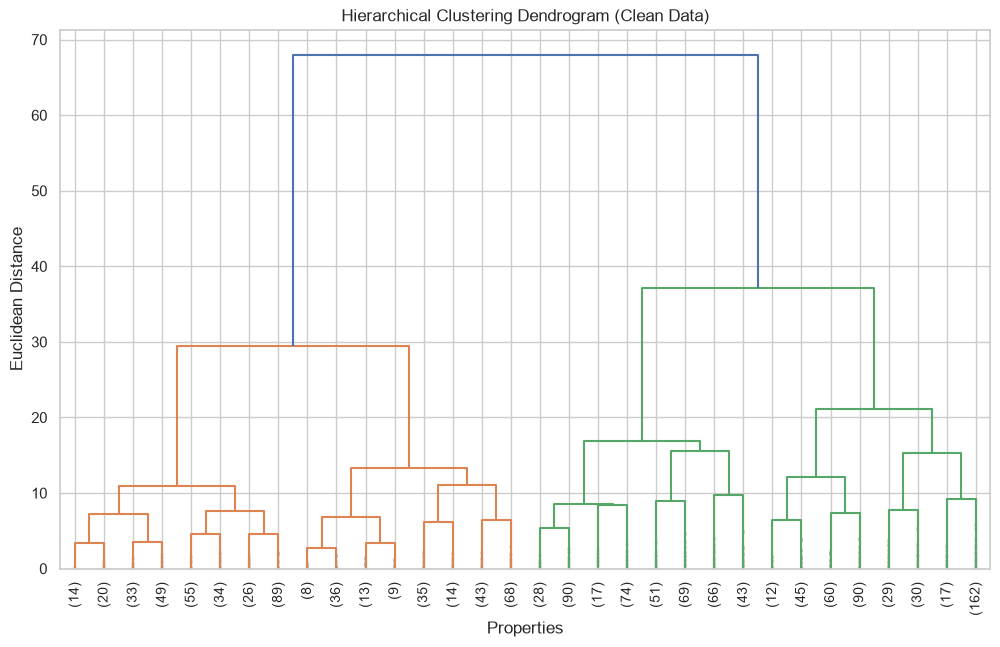

In [2]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 7))
plt.title("Hierarchical Clustering Dendrogram (Clean Data)")
plt.xlabel("Properties")
plt.ylabel("Euclidean Distance")

# We truncate it slightly so the screen isn't filled with 1,400 tiny leaves
dendrogram(Z, truncate_mode='level', p=4, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.show()

### 2. The Decision (Where to Cut)
By analyzing the Euclidean distances on the Y-axis above, we can see that the three longest continuous vertical branches exist between `Y=29.5` and `Y=37.1`. 

If we draw a horizontal slice right through the middle at `Y=33`, the line will perfectly intersect exactly 3 main branches. Let's visualize this cut.

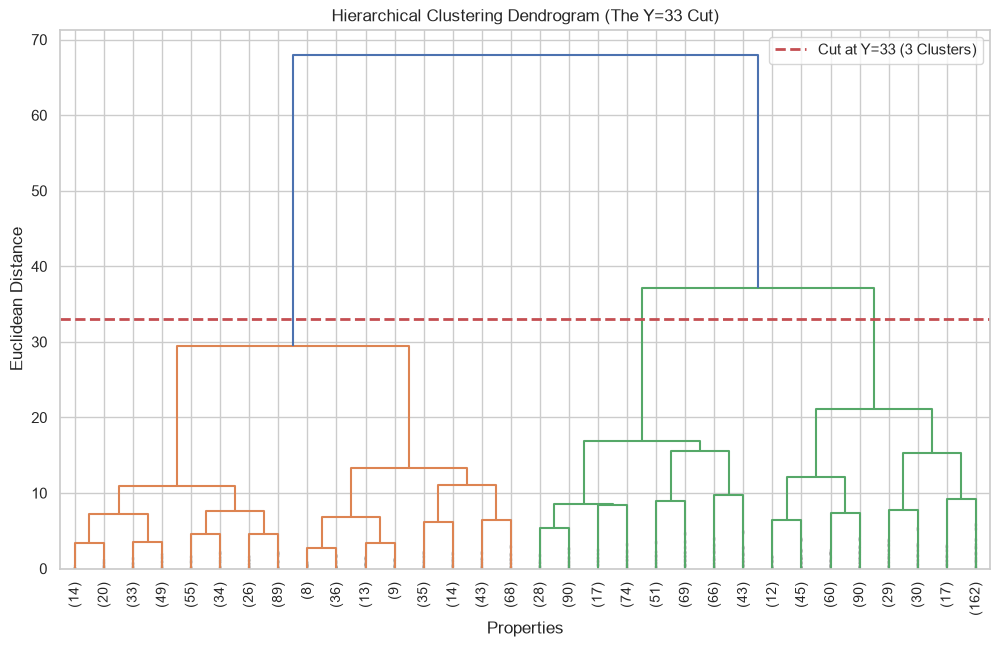

In [3]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 7))
plt.title("Hierarchical Clustering Dendrogram (The Y=33 Cut)")
plt.xlabel("Properties")
plt.ylabel("Euclidean Distance")

# We truncate it slightly so the screen isn't filled with 1,400 tiny leaves
dendrogram(Z, truncate_mode='level', p=4, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.axhline(y=33, color='r', linestyle='--', linewidth=2, label='Cut at Y=33 (3 Clusters)')
plt.legend()
plt.show()

### 3. Extracting the 3 Final Tiers
Because DBSCAN already removed the extreme anomalies, these 3 branches perfectly and naturally represent the standard suburban market. We will extract them and map them to Starter, Mid-Market, and Luxury.

In [4]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
X_raw['Market_Tier'] = hc.fit_predict(X_scaled)
X_raw['SalePrice'] = pd.read_csv('../../data/processed/y_cluster_clean_price.csv').squeeze()

# Analyze the centroids
centroids = X_raw.groupby('Market_Tier').mean().round(1).sort_values('SalePrice')

tier_mapping = {
    centroids.index[0]: 'Starter Home',
    centroids.index[1]: 'Mid-Market Suburban',
    centroids.index[2]: 'Luxury Estate'
}
centroids.index = tier_mapping.values()
X_raw['Market_Tier'] = X_raw['Market_Tier'].map(tier_mapping)
display(centroids)

,TotalSF,OverallQual,YearBuilt,LotArea,GarageCars,SalePrice
Starter Home,2015.2,5.1,1948.1,8352.6,0.8,122053.3
Mid-Market Suburban,2461.2,5.6,1958.8,10917.6,2.0,159135.3
Luxury Estate,2999.6,7.3,2001.1,9816.8,2.3,238987.5


### 4. PCA Visualization & Export
We will use Principal Component Analysis (PCA) to project our 5-dimensional data onto a 2D screen, allowing us to cleanly see the 3 business tiers.

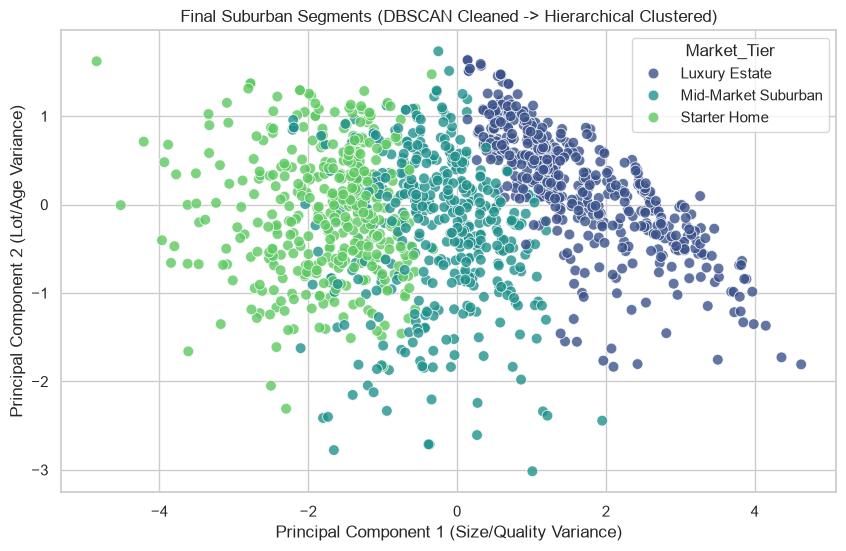

Model mathematically justified, visualized, and saved!


In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_raw['PCA1'] = X_pca[:, 0]
X_raw['PCA2'] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=X_raw, x='PCA1', y='PCA2', hue='Market_Tier', palette='viridis', alpha=0.8, s=60)
plt.title('Final Suburban Segments (DBSCAN Cleaned -> Hierarchical Clustered)')
plt.xlabel('Principal Component 1 (Size/Quality Variance)')
plt.ylabel('Principal Component 2 (Lot/Age Variance)')
plt.show()

# Save final models for the web app
joblib.dump(hc, '../../models/hierarchical_tier_model.pkl')
joblib.dump(tier_mapping, '../../models/tier_mapping.pkl')
print("Model mathematically justified, visualized, and saved!")